In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE_DIR = "/content/drive/MyDrive/cognitive_mirror"

VIDEO_DIR = os.path.join(BASE_DIR, "video")
RESULTS_DIR = os.path.join(VIDEO_DIR, "video_results")
FRAMES_DIR = os.path.join(RESULTS_DIR, "frames")

os.makedirs(FRAMES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Video folder created:", VIDEO_DIR)

Mounted at /content/drive
Video folder created: /content/drive/MyDrive/cognitive_mirror/video


In [2]:
!pip install -q opencv-python-headless gradio pandas matplotlib

In [8]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

Found existing installation: opencv-python 5.1.0.95
Uninstalling opencv-python-5.1.0.95:
  Successfully uninstalled opencv-python-5.1.0.95


In [9]:
!pip install -q opencv-python-headless

In [ ]:
# Cleanly install opencv-python-headless
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install -q opencv-python-headless

import os
print("Reinstallation complete. Restarting runtime to force Python to reload the new OpenCV bindings...")
# Restart runtime
os._exit(00)

Found existing installation: opencv-python-headless 5.1.0.95
Uninstalling opencv-python-headless-5.1.0.95:
  Successfully uninstalled opencv-python-headless-5.1.0.95


In [ ]:
import os
print("Restarting Colab runtime to force reload clean OpenCV bindings...")
os._exit(0)

In [2]:
import cv2
import sys
import importlib.util

print("Python version:", sys.version)
print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("OpenCV location:", getattr(cv2, "__file__", "Unknown"))
print("CascadeClassifier exists:", hasattr(cv2, "CascadeClassifier"))
print("OpenCV data exists:", hasattr(cv2, "data"))

print("\nModule information:")
print(importlib.util.find_spec("cv2"))

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
OpenCV version: 5.1.0
OpenCV location: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
CascadeClassifier exists: False
OpenCV data exists: True

Module information:
ModuleSpec(name='cv2', loader=<google.colab._import_hooks._hook_injector.HookInjectorLoader object at 0x799bc0c9ae40>)


In [3]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

!pip install --no-cache-dir opencv-python-headless==4.10.0.84

Found existing installation: opencv-python-headless 5.1.0.95
Uninstalling opencv-python-headless-5.1.0.95:
  Successfully uninstalled opencv-python-headless-5.1.0.95
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 74.6 MB/s  0:00:00


In [1]:
import cv2

print("Version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

detector = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

print("Face detector loaded:", not detector.empty())

Version: 4.10.0
CascadeClassifier: True
Face detector loaded: True


In [7]:
import sys
print(sys.version)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [8]:
!pip install mediapipe==1.2.3

  Using cached mediapipe-1.2.3-py3-none-manylinux_2_28_x86_64.whl.metadata (10 kB)
  Using cached opencv_contrib_python-5.1.0.95-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (20 kB)
Using cached mediapipe-1.2.3-py3-none-manylinux_2_28_x86_64.whl (43.3 MB)
Using cached opencv_contrib_python-5.1.0.95-cp37-abi3-manylinux_2_28_x86_64.whl (89.0 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mediapipe]


In [1]:
import mediapipe as mp
import cv2
import sys

print("Python:", sys.version)
print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe location:", mp.__file__)
print("Has solutions:", hasattr(mp, "solutions"))
print("Has tasks:", hasattr(mp, "tasks"))

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
MediaPipe: 1.2.3
OpenCV: 5.1.0
MediaPipe location: /usr/local/lib/python3.13/dist-packages/mediapipe/__init__.py
Has solutions: False
Has tasks: True


In [2]:
import os

MODEL_DIR = "/content/drive/MyDrive/cognitive_mirror/video"
os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "blaze_face_short_range.tflite"
)

if not os.path.exists(MODEL_PATH):
    !wget -q -O "$MODEL_PATH" https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite

print("Model downloaded:", os.path.exists(MODEL_PATH))

Model downloaded: True


In [3]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

base_options = python.BaseOptions(
    model_asset_path=MODEL_PATH
)

options = vision.FaceDetectorOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    min_detection_confidence=0.6
)

mp_face_detector = vision.FaceDetector.create_from_options(
    options
)

print("MediaPipe Tasks Face Detector loaded successfully!")

MediaPipe Tasks Face Detector loaded successfully!


In [7]:
options = vision.FaceDetectorOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    min_detection_confidence=0.4
)

mp_face_detector = vision.FaceDetector.create_from_options(
    options
)

Saving WhatsApp Video 2026-11-25 at 2.52.34 PM.mp4 to WhatsApp Video 2026-11-25 at 2.52.34 PM (2).mp4
Detected video file 'WhatsApp Video 2026-11-25 at 2.52.34 PM (2).mp4'. Extracting first frame for face detection...
Faces detected: 2


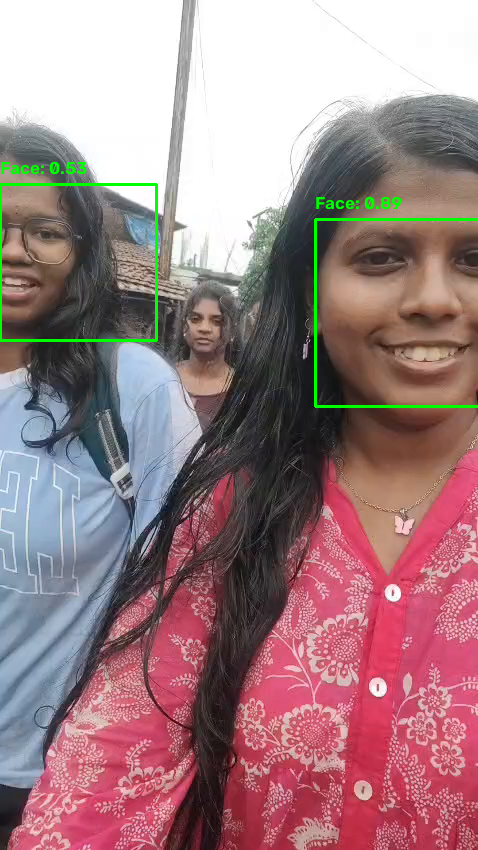

In [8]:
import cv2
import os
import mediapipe as mp
from google.colab.patches import cv2_imshow
from google.colab import files

# Upload a file (image or video) to test
uploaded = files.upload()

if not uploaded:
    print("No file uploaded.")
else:
    file_path = next(iter(uploaded))
    ext = os.path.splitext(file_path)[1].lower()
    image = None

    # If the user uploaded a video, extract the first frame to test face detection
    if ext in [".mp4", ".avi", ".mov", ".mkv"]:
        print(f"Detected video file '{file_path}'. Extracting first frame for face detection...")
        cap = cv2.VideoCapture(file_path)
        success, frame = cap.read()
        cap.release()
        if success:
            image = frame
        else:
            print("Failed to extract frame from the video.")
    else:
        # Otherwise, treat it as a static image
        image = cv2.imread(file_path)

    if image is None:
        print("Error: Could not load image data from the uploaded file.")
    else:
        rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_image
        )

        # Run face detection
        result = mp_face_detector.detect(mp_image)

        if result.detections:
            for detection in result.detections:
                bbox = detection.bounding_box
                x, y, w, h = bbox.origin_x, bbox.origin_y, bbox.width, bbox.height
                confidence = detection.categories[0].score

                # Draw boxes
                cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
                cv2.putText(
                    image,
                    f"Face: {confidence:.2f}",
                    (x, max(20, y - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (0, 255, 0),
                    2
                )

        print("Faces detected:", len(result.detections) if result.detections else 0)
        cv2_imshow(image)

In [9]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE_DIR = "/content/drive/MyDrive/cognitive_mirror"
VIDEO_DIR = os.path.join(BASE_DIR, "video")
RESULTS_DIR = os.path.join(VIDEO_DIR, "video_results")
FRAMES_DIR = os.path.join(RESULTS_DIR, "frames")
MODEL_DIR = VIDEO_DIR

os.makedirs(FRAMES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Video folders created successfully!")
print(VIDEO_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Video folders created successfully!
/content/drive/MyDrive/cognitive_mirror/video


In [10]:
MODEL_PATH = os.path.join(
    VIDEO_DIR,
    "blaze_face_short_range.tflite"
)

if os.path.exists(MODEL_PATH):
    print("Face detection model saved successfully!")
else:
    print("Model not found. Download it again before continuing.")

Face detection model saved successfully!


In [11]:

%%writefile /content/video_analysis.py

import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp

from datetime import datetime
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BASE_DIR = "/content/drive/MyDrive/cognitive_mirror/video"

RESULTS_DIR = os.path.join(BASE_DIR, "video_results")
FRAMES_DIR = os.path.join(RESULTS_DIR, "frames")
MODEL_PATH = os.path.join(BASE_DIR, "blaze_face_short_range.tflite")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FRAMES_DIR, exist_ok=True)

face_detector = None


def load_models():

    global face_detector

    if face_detector is None:

        base_options = python.BaseOptions(
            model_asset_path=MODEL_PATH
        )

        options = vision.FaceDetectorOptions(
            base_options=base_options,
            running_mode=vision.RunningMode.IMAGE,
            min_detection_confidence=0.4
        )

        face_detector = vision.FaceDetector.create_from_options(
            options
        )

    return face_detector


def analyze_video(video_path, sample_interval=1):

    if video_path is None:
        raise ValueError("Please upload an MP4 video.")

    detector = load_models()

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise ValueError("Could not open the uploaded video.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0:
        cap.release()
        raise ValueError("Invalid video FPS.")

    duration = total_frames / fps

    rows = []
    gallery = []

    frame_number = 0
    saved_frame_number = 0

    while True:

        success, frame = cap.read()

        if not success:
            break

        timestamp = frame_number / fps

        if frame_number % max(1, int(fps * sample_interval)) == 0:

            rgb = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            result = detector.detect(mp_image)

            face_count = len(result.detections)

            for detection in result.detections:

                bbox = detection.bounding_box

                x = max(0, bbox.origin_x)
                y = max(0, bbox.origin_y)
                w = bbox.width
                h = bbox.height

                confidence = detection.categories[0].score

                cv2.rectangle(
                    frame,
                    (x, y),
                    (x + w, y + h),
                    (0, 255, 0),
                    2
                )

                cv2.putText(
                    frame,
                    f"Face {confidence:.2f}",
                    (x, max(20, y - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (0, 255, 0),
                    2
                )

            filename = f"frame_{saved_frame_number}.jpg"

            frame_path = os.path.join(
                FRAMES_DIR,
                filename
            )

            cv2.imwrite(frame_path, frame)

            gallery.append((frame_path, f"Time: {timestamp:.2f}s"))

            rows.append({
                "Frame": frame_number,
                "Timestamp (seconds)": round(timestamp, 2),
                "Faces Detected": face_count
            })

            saved_frame_number += 1

        frame_number += 1

    cap.release()

    df = pd.DataFrame(rows)

    graph_path = os.path.join(
        RESULTS_DIR,
        "face_detection_graph.png"
    )

    plt.figure(figsize=(10, 5))

    if not df.empty:
        plt.plot(
            df["Timestamp (seconds)"],
            df["Faces Detected"],
            marker="o"
        )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Number of Faces")
    plt.title("Video Face Detection Analysis")
    plt.grid(True)
    plt.savefig(graph_path)
    plt.close()

    json_path = os.path.join(
        RESULTS_DIR,
        "video_analysis.json"
    )

    report = {
        "video_name": os.path.basename(video_path),
        "duration_seconds": round(duration, 2),
        "fps": round(fps, 2),
        "total_frames": total_frames,
        "sample_interval_seconds": sample_interval,
        "frames_analyzed": len(rows),
        "total_faces_detected_across_samples": int(
            df["Faces Detected"].sum()
        ) if not df.empty else 0,
        "frame_results": rows,
        "created_at": datetime.now().isoformat()
    }

    with open(json_path, "w") as f:
        json.dump(report, f, indent=4)

    summary = (
        f"Video Analysis Completed!\n"
        f"Duration: {duration:.2f} seconds\n"
        f"FPS: {fps:.2f}\n"
        f"Frames analyzed: {len(rows)}\n"
        f"Total face detections across sampled frames: "
        f"{report['total_faces_detected_across_samples']}"
    )

    return gallery, df, graph_path, summary, json_path


def build_demo():

    import gradio as gr

    with gr.Blocks(title="Cognitive Mirror Video Analysis") as demo:

        gr.Markdown("# Cognitive Mirror – Video Analysis")

        video_input = gr.Video(
            sources=["upload"],
            format="mp4",
            label="Upload MP4 Video"
        )

        interval_input = gr.Slider(
            minimum=1,
            maximum=5,
            value=1,
            step=1,
            label="Frame Extraction Interval (seconds)"
        )

        analyze_button = gr.Button(
            "Analyze Video",
            variant="primary"
        )

        gallery = gr.Gallery(
            label="Detected Faces",
            columns=3
        )

        table = gr.Dataframe(
            label="Frame Analysis"
        )

        graph = gr.Image(
            label="Face Detection Graph"
        )

        summary = gr.Textbox(
            label="Video Summary",
            lines=6
        )

        json_file = gr.File(
            label="Download JSON Results"
        )

        analyze_button.click(
            fn=analyze_video,
            inputs=[video_input, interval_input],
            outputs=[
                gallery,
                table,
                graph,
                summary,
                json_file
            ]
        )

    return demo


Writing /content/video_analysis.py


In [12]:
import shutil
import os

SOURCE = "/content/video_analysis.py"

DESTINATION = os.path.join(
    VIDEO_DIR,
    "video_analysis.py"
)

shutil.copy2(SOURCE, DESTINATION)

print("Video analysis module saved!")
print(DESTINATION)

Video analysis module saved!
/content/drive/MyDrive/cognitive_mirror/video/video_analysis.py


In [13]:
import sys
import importlib

if VIDEO_DIR not in sys.path:
    sys.path.insert(0, VIDEO_DIR)

import video_analysis

importlib.reload(video_analysis)

video_analysis.load_models()

print("Video module imported successfully!")
print("MediaPipe model loaded successfully!")

Video module imported successfully!
MediaPipe model loaded successfully!


In [14]:
import sys
import os
import gradio as gr

BASE_DIR = "/content/drive/MyDrive/cognitive_mirror"
VIDEO_DIR = os.path.join(BASE_DIR, "video")

sys.path.insert(0, VIDEO_DIR)

import video_analysis

video_analysis.load_models()

print("Video Analysis ready for GUI!")

Video Analysis ready for GUI!


In [15]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import gradio as gr
import importlib

VIDEO_DIR = "/content/drive/MyDrive/cognitive_mirror/video"

sys.path.insert(0, VIDEO_DIR)

import video_analysis
importlib.reload(video_analysis)

video_analysis.load_models()

print("Video Analysis module loaded successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Video Analysis module loaded successfully!


In [17]:
import os

SEARCH_DIRS = [
    "/content/drive/MyDrive/cognitive_mirror",
    "/content/drive/MyDrive/Colab Notebooks"
]

model_files = []

for search_dir in SEARCH_DIRS:
    if os.path.exists(search_dir):
        for root, dirs, files in os.walk(search_dir):
            # Avoid searching unnecessary hidden folders
            dirs[:] = [d for d in dirs if not d.startswith(".")]

            for file in files:
                if file.endswith((".pth", ".pt")):
                    model_files.append(
                        os.path.join(root, file)
                    )

print("PyTorch model files found:")

for path in model_files:
    print(path)

if not model_files:
    print("No .pth or .pt files found in these folders.")

PyTorch model files found:
/content/drive/MyDrive/cognitive_mirror/transformer_model.pt
/content/drive/MyDrive/cognitive_mirror/transformer_model_backup.pt
/content/drive/MyDrive/cognitive_mirror/diffusion_unet_ema.pt
/content/drive/MyDrive/cognitive_mirror/ae_latent_stats.pt
/content/drive/MyDrive/cognitive_mirror/vae_model.pt
/content/drive/MyDrive/cognitive_mirror/gan_generator.pt
/content/drive/MyDrive/cognitive_mirror/ae_model.pt
/content/drive/MyDrive/cognitive_mirror/gan_discriminator.pt
